In [1]:
pip install numpy pandas matplotlib scikit-learn tensorflow

Note: you may need to restart the kernel to use updated packages.


Dataset Shape: (2906327, 8)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2906327 entries, 0 to 2906326
Data columns (total 8 columns):
 #   Column          Dtype  
---  ------          -----  
 0   Region          object 
 1   Country         object 
 2   State           object 
 3   City            object 
 4   Month           int64  
 5   Day             int64  
 6   Year            int64  
 7   AvgTemperature  float64
dtypes: float64(1), int64(3), object(4)
memory usage: 177.4+ MB
None

Columns:
Index(['Region', 'Country', 'State', 'City', 'Month', 'Day', 'Year',
       'AvgTemperature'],
      dtype='object')

Missing Values:
Region                  0
Country                 0
State             1450990
City                    0
Month                   0
Day                     0
Year                    0
AvgTemperature          0
dtype: int64

Total Cities: 321

Available Cities:
['Algiers' 'Bujumbura' 'Cotonou' 'Bangui' 'Brazzaville' 'Cairo'
 'Addis Abab

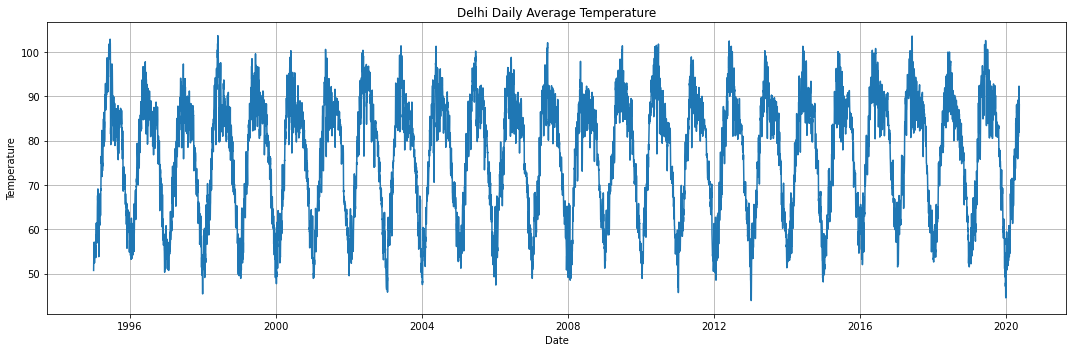


Training Samples: (7364, 1)
Testing Samples: (1841, 1)

Training Input Shape: (7334, 30, 1)
Training Output Shape: (7334, 1)
Testing Input Shape: (1841, 30, 1)
Testing Output Shape: (1841, 1)

Original Sequences:
[[1, 2, 3], [4, 5], [6, 7, 8, 9]]

Padded Sequences:
[[0 0 1 2 3]
 [0 0 0 4 5]
 [0 6 7 8 9]]

Final Training Shape: (6601, 30, 1)
Validation Shape: (733, 30, 1)

SIMPLE RNN MODEL SUMMARY
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 simple_rnn (SimpleRNN)      (None, 64)                4224      
                                                                 
 dense (Dense)               (None, 32)                2080      
                                                                 
 dense_1 (Dense)             (None, 1)                 33        
                                                                 
Total params: 6337 (24.75 KB)
Trainable params: 633

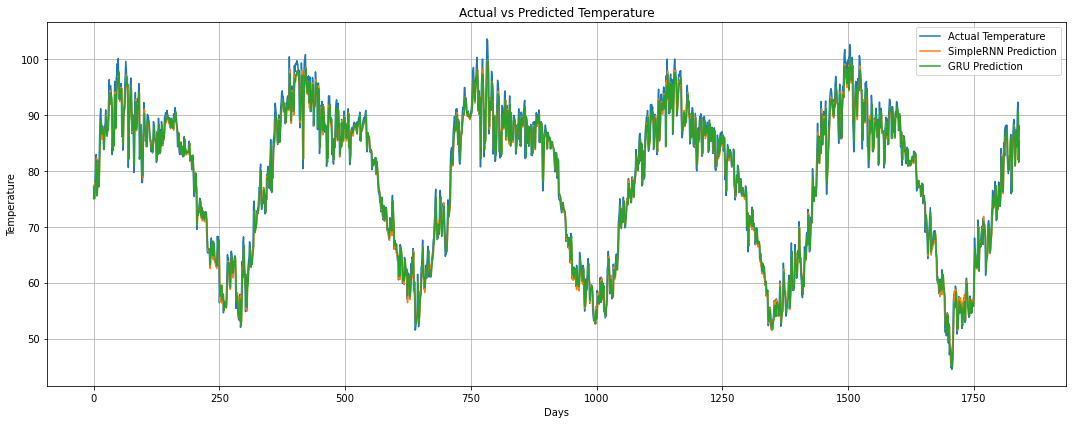

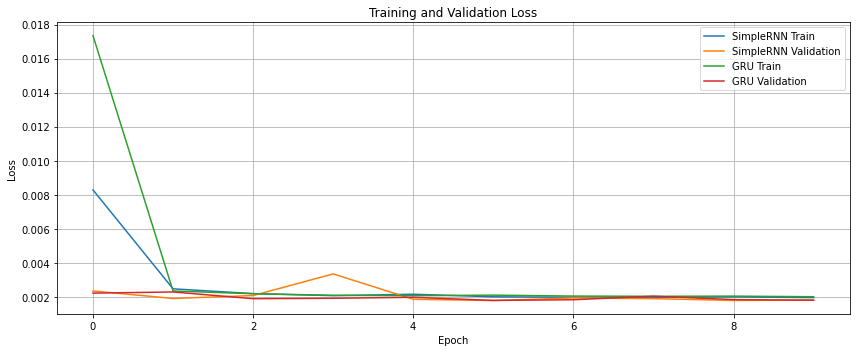


========== MODEL COMPARISON ==========
    Model     Loss  MAE (Scaled)  MSE (Temperature)  MAE (Temperature)
SimpleRNN 0.002168      0.035384           7.754307           2.115968
      GRU 0.002207      0.035637           7.892829           2.131090

TASK 7 EXECUTED SUCCESSFULLY!


In [5]:

# ============================================================
# TASK 7: DAILY TEMPERATURE PREDICTION USING SimpleRNN AND GRU
# ============================================================

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, GRU, Dense
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# ------------------------------------------------------------
# 1. LOAD DATASET
# ------------------------------------------------------------

DATA_PATH = r"city_temperature.csv"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Please update DATA_PATH with your CSV file location."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset Shape:", df.shape)
print("\nDataset Information:")
print(df.info())

print("\nColumns:")
print(df.columns)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTotal Cities:", df["City"].nunique())
print("\nAvailable Cities:")
print(df["City"].unique()[:20])

# ------------------------------------------------------------
# 2. SELECT DELHI CITY DATA
# ------------------------------------------------------------

city_df = df[df["City"] == "Delhi"].copy()

# Remove invalid temperature values
city_df = city_df[city_df["AvgTemperature"] != -99]

# Remove missing required values
city_df = city_df.dropna(
    subset=["Year", "Month", "Day", "AvgTemperature"]
)

# Create Date column
city_df["Date"] = pd.to_datetime(
    city_df[["Year", "Month", "Day"]]
)

# Sort data by date
city_df = city_df.sort_values("Date")
city_df = city_df.reset_index(drop=True)

print("\nDelhi Dataset Shape:", city_df.shape)
print(city_df.head())

# Extract temperature
temperature = city_df[["AvgTemperature"]].values

print("\nTemperature Shape:", temperature.shape)

# ------------------------------------------------------------
# 3. VISUALIZE DAILY TEMPERATURE
# ------------------------------------------------------------

plt.figure(figsize=(15, 5))

plt.plot(city_df["Date"], temperature)

plt.title("Delhi Daily Average Temperature")
plt.xlabel("Date")
plt.ylabel("Temperature")
plt.grid(True)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. NORMALIZE DATA
# ------------------------------------------------------------

# Chronological 80:20 split
train_size = int(len(temperature) * 0.80)

train_raw = temperature[:train_size]
test_raw = temperature[train_size:]

# Fit scaler only on training data
scaler = MinMaxScaler()

train = scaler.fit_transform(train_raw)
test = scaler.transform(test_raw)

print("\nTraining Samples:", train.shape)
print("Testing Samples:", test.shape)

# ------------------------------------------------------------
# 5. CREATE TIME SERIES SEQUENCES
# ------------------------------------------------------------

lookback = 30
batch_size = 32

def create_sequences(data, lookback):
    X = []
    y = []

    for i in range(len(data) - lookback):
        X.append(data[i:i + lookback])
        y.append(data[i + lookback])

    return np.array(X), np.array(y)


# Training sequences
X_train, y_train = create_sequences(train, lookback)

# Use previous 30 training days as context for test predictions
test_with_context = np.concatenate(
    (train[-lookback:], test),
    axis=0
)

X_test, y_test = create_sequences(
    test_with_context, lookback
)

print("\nTraining Input Shape:", X_train.shape)
print("Training Output Shape:", y_train.shape)

print("Testing Input Shape:", X_test.shape)
print("Testing Output Shape:", y_test.shape)

# ------------------------------------------------------------
# 6. PADDING SEQUENCES
# ------------------------------------------------------------

sample_sequences = [
    [1, 2, 3],
    [4, 5],
    [6, 7, 8, 9]
]

padded = pad_sequences(
    sample_sequences,
    maxlen=5,
    padding="pre"
)

print("\nOriginal Sequences:")
print(sample_sequences)

print("\nPadded Sequences:")
print(padded)

# ------------------------------------------------------------
# 7. SPLIT TRAINING DATA INTO TRAIN AND VALIDATION
# ------------------------------------------------------------

validation_size = int(len(X_train) * 0.10)

if validation_size == 0:
    raise ValueError("Not enough training samples for validation.")

X_val = X_train[-validation_size:]
y_val = y_train[-validation_size:]

X_train_final = X_train[:-validation_size]
y_train_final = y_train[:-validation_size]

print("\nFinal Training Shape:", X_train_final.shape)
print("Validation Shape:", X_val.shape)

# ------------------------------------------------------------
# 8. CREATE CALLBACKS
# ------------------------------------------------------------

def get_callbacks():
    return [
        EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            verbose=1
        )
    ]

# ------------------------------------------------------------
# 9. SIMPLE RNN MODEL
# ------------------------------------------------------------

simple_rnn = Sequential([
    tf.keras.layers.Input(shape=(lookback, 1)),

    SimpleRNN(
        64,
        activation="tanh"
    ),

    Dense(32, activation="relu"),

    Dense(1)
])

print("\nSIMPLE RNN MODEL SUMMARY")
simple_rnn.summary()

simple_rnn.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

# Train SimpleRNN
history_rnn = simple_rnn.fit(
    X_train_final,
    y_train_final,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=batch_size,
    callbacks=get_callbacks(),
    verbose=1
)

# Evaluate SimpleRNN
loss_rnn, mae_rnn = simple_rnn.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("\nSimpleRNN Loss:", loss_rnn)
print("SimpleRNN MAE:", mae_rnn)

# ------------------------------------------------------------
# 10. STATEFUL SIMPLE RNN MODEL
# ------------------------------------------------------------

stateful_rnn = Sequential([
    tf.keras.layers.Input(batch_shape=(1, lookback, 1)),

    SimpleRNN(
        32,
        stateful=True
    ),

    Dense(1)
])

stateful_rnn.compile(
    optimizer="adam",
    loss="mse"
)

print("\nStateful SimpleRNN Created Successfully")
stateful_rnn.summary()

# ------------------------------------------------------------
# 11. GRU MODEL
# ------------------------------------------------------------

gru_model = Sequential([
    tf.keras.layers.Input(shape=(lookback, 1)),

    GRU(
        64,
        activation="tanh"
    ),

    Dense(32, activation="relu"),

    Dense(1)
])

print("\nGRU MODEL SUMMARY")
gru_model.summary()

gru_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

# Train GRU
history_gru = gru_model.fit(
    X_train_final,
    y_train_final,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=batch_size,
    callbacks=get_callbacks(),
    verbose=1
)

# Evaluate GRU
loss_gru, mae_gru = gru_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("\nGRU Loss:", loss_gru)
print("GRU MAE:", mae_gru)

# ------------------------------------------------------------
# 12. PREDICTION USING BOTH MODELS
# ------------------------------------------------------------

pred_rnn = simple_rnn.predict(X_test)
pred_gru = gru_model.predict(X_test)

# Convert normalized values back to original temperature
pred_rnn = scaler.inverse_transform(pred_rnn)
pred_gru = scaler.inverse_transform(pred_gru)

actual = scaler.inverse_transform(y_test)

# ------------------------------------------------------------
# 13. CALCULATE ERROR METRICS
# ------------------------------------------------------------

mse_rnn = mean_squared_error(actual, pred_rnn)
mae_rnn_original = mean_absolute_error(actual, pred_rnn)

mse_gru = mean_squared_error(actual, pred_gru)
mae_gru_original = mean_absolute_error(actual, pred_gru)

print("\n========== MODEL PERFORMANCE ==========")

print("\nSimpleRNN")
print("MSE:", mse_rnn)
print("MAE:", mae_rnn_original)

print("\nGRU")
print("MSE:", mse_gru)
print("MAE:", mae_gru_original)

# ------------------------------------------------------------
# 14. ACTUAL VS PREDICTED TEMPERATURE
# ------------------------------------------------------------

plt.figure(figsize=(15, 6))

plt.plot(actual, label="Actual Temperature")
plt.plot(pred_rnn, label="SimpleRNN Prediction")
plt.plot(pred_gru, label="GRU Prediction")

plt.title("Actual vs Predicted Temperature")
plt.xlabel("Days")
plt.ylabel("Temperature")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 15. TRAINING AND VALIDATION LOSS
# ------------------------------------------------------------

plt.figure(figsize=(12, 5))

plt.plot(
    history_rnn.history["loss"],
    label="SimpleRNN Train"
)

plt.plot(
    history_rnn.history["val_loss"],
    label="SimpleRNN Validation"
)

plt.plot(
    history_gru.history["loss"],
    label="GRU Train"
)

plt.plot(
    history_gru.history["val_loss"],
    label="GRU Validation"
)

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 16. MODEL COMPARISON
# ------------------------------------------------------------

comparison = pd.DataFrame({
    "Model": ["SimpleRNN", "GRU"],

    "Loss": [loss_rnn, loss_gru],

    "MAE (Scaled)": [mae_rnn, mae_gru],

    "MSE (Temperature)": [mse_rnn, mse_gru],

    "MAE (Temperature)": [
        mae_rnn_original,
        mae_gru_original
    ]
})

print("\n========== MODEL COMPARISON ==========")
print(comparison.to_string(index=False))

print("\nTASK 7 EXECUTED SUCCESSFULLY!")
